# [13.4] Sparse Autoencoders for Diffusion Models (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter13_image_generation_interpretability/exercises/part4_diffusion_saes/13.4_Sparse_Autoencoders_for_Diffusion_Models_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter13_image_generation_interpretability/exercises/part4_diffusion_saes/13.4_Sparse_Autoencoders_for_Diffusion_Models_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

Two bright objects share a background: a red square and a blue square. A hidden vector mixes
their colors with background and stripe information. If a sparse feature activates on the red
square, does turning it off remove the square's redness, or does it just damage the image?

By the end of this notebook, you will have shown that residual-preserving sparse-feature
ablation selectively changes one object's color in an explicit image generator, because
pixel contrast drops in the target mask while a nuisance-feature control fails that target
score and reconstruction-only replacement loses unrelated detail.

Prerequisites: sparse coding in chapter 6, dot products, and the diffusion intervention
vocabulary of 13.1–13.2. No SAE is fitted to native diffusion activations here. A known
orthonormal dictionary makes every reconstruction error and causal effect checkable.

## Study-edition boundary

The default path is a small, deterministic CPU organism with explicit weights and finite
images. It teaches the named component operations and controls. It is not a trained diffusion
model, a pretrained checkpoint, or a paper replication. No model download, GPU selection,
training run or scientific sweep occurs.

## Content & Learning Objectives

### 1️⃣ Image-generating mixtures

Treat image-generating hidden states as mixtures of sparse components.

> ##### Learning Objectives
>
> - Implement the visible operations for treat image-generating hidden states as mixtures of sparse components.
> - Explain the tensor axes and use an independent small-case check.

### 2️⃣ Sparse reconstruction and its errors

Implement sparse encoding, decoding and the reconstruction/sparsity trade-off.

> ##### Learning Objectives
>
> - Implement the visible operations for implement sparse encoding, decoding and the reconstruction/sparsity trade-off.
> - Explain the tensor axes and use an independent small-case check.

### 3️⃣ Feature interventions without losing the residual

Ablate or amplify one feature while preserving the reconstruction residual.

> ##### Learning Objectives
>
> - Implement the visible operations for ablate or amplify one feature while preserving the reconstruction residual.
> - Explain the tensor axes and use an independent small-case check.

### 4️⃣ Correlation, causation and transfer

Measure intervention specificity and distinguish a nuisance correlation from a causal effect.

> ##### Learning Objectives
>
> - Implement the visible operations for measure intervention specificity and distinguish a nuisance correlation from a causal effect.
> - Explain the tensor axes and use an independent small-case check.

### ☆ Bonus

Anomaly hunts, the source-grounded model bridge, and further reading.

## Setup code

Use the existing environment and keep the notebook under this checkout. No installation cell
is needed. All arrays use NumPy float64 on CPU. The section-local helpers provide plotting
only; each method, metric, intervention and control is implemented below.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

chapter = "chapter13_image_generation_interpretability"
section = "part4_diffusion_saes"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).is_dir())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part4_diffusion_saes.tests as tests
import part4_diffusion_saes.utils as utils
MAIN = __name__ == "__main__"

# 1️⃣ Image-generating mixtures

> ##### Learning Objectives
>
> - Implement the visible operations for treat image-generating hidden states as mixtures of sparse components.
> - Explain the tensor axes and use an independent small-case check.

The activation has width four. Three unit decoder rows encode left-object red, right-object
blue and a shared background factor:
$$d_0=(1,0,1,0)/\sqrt2,\quad d_1=(0,1,0,1)/\sqrt2,\quad d_2=(1,1,-1,-1)/2.$$
The remaining unit direction $r=(1,-1,-1,1)/2$ carries a gray stripe. It is deliberately
**outside** the dictionary. This missing component is the reason we preserve residuals.
Activations have shape `[batch,4]`; sparse codes `[batch,3]`; decoder `[3,4]`.

The renderer below reads these factors into two spatially separated colored squares. It is
a planted image-generation organism, not a discovered feature dictionary in a UNet.

### Exercise - implement `sparse_encode`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement $z=\mathrm{ReLU}(xE^T-\theta)$. The scalar threshold is subtracted before ReLU,
not after. The batch axis must be preserved.

In [2]:
def sparse_encode(activations, encoder, threshold):
    return np.maximum(np.asarray(activations) @ np.asarray(encoder).T - threshold, 0.)


tests.test_sparse_encode(sparse_encode)

All tests in test_sparse_encode passed!


<details><summary>Hint</summary>

Project activations into feature rows, then threshold.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_sparse_encode passed!`.
For `x=[2,-1]`, identity encoder and threshold 0.5, z is `[1.5,0]`.

</details>

### Exercise - implement `sparse_decode`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Reconstruct `[batch,width]` activations from `[batch,features]` codes and `[features,width]` decoder rows.

In [3]:
def sparse_decode(codes, decoder):
    return np.asarray(codes) @ np.asarray(decoder)


tests.test_sparse_decode(sparse_decode)

All tests in test_sparse_decode passed!


<details><summary>Hint</summary>

Each code multiplies one dictionary row.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_sparse_decode passed!`.
An all-zero code reconstructs zero; it is not automatically a valid activation baseline.

</details>

## Read activations into pixels

For each activation row $x=(x_0,x_1,x_2,x_3)$, compute four scalar readouts:

$$
\ell=(x_0+x_2)/\sqrt2,\qquad r=(x_1+x_3)/\sqrt2,\qquad
b=(x_0+x_1-x_2-x_3)/2,\qquad s=(x_0-x_1-x_2+x_3)/2.
$$

Create an RGB image of height8 and width10. All indices below are zero based and slices
exclude the final endpoint. First fill **every pixel and every channel** with the gray
background value $0.2+0.1b$. Then overwrite the left square at rows `2:6`, columns `1:4`
with RGB $(0.2+0.7\ell,\ 0.2,\ 0.2)$ and the right square at rows `2:6`, columns `6:9`
with RGB $(0.2,\ 0.2,\ 0.2+0.7r)$. After painting both squares, add $0.1s$ to all three
channels of **every pixel in row3**, including the background. Finally clip all RGB values
to `[0,1]`, and return shape `[batch,8,10,3]` (add a batch axis for a single activation).

For $x=(1,0,1,0)/\sqrt2$, the readouts are $\ell=1$ and $r=b=s=0$.
Thus a left-square pixel is exactly `[0.9,0.2,0.2]`, a right-square pixel is
`[0.2,0.2,0.2]`, and a background pixel is `[0.2,0.2,0.2]`. This is the numerical
contract checked below; you do not need to infer any renderer constants from the solution.

### Exercise - implement `render_sparse_scene`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Render the explicit readouts above into `[batch,8,10,3]` images. Both squares span rows2:6; left columns1:4, right6:9. Add the stripe to row3 in every channel.

In [4]:
def render_sparse_scene(activations):
    x = np.atleast_2d(np.asarray(activations,dtype=np.float64))
    left = (x[:,0]+x[:,2])/np.sqrt(2)
    right = (x[:,1]+x[:,3])/np.sqrt(2)
    background = (x[:,0]+x[:,1]-x[:,2]-x[:,3])/2
    stripe = (x[:,0]-x[:,1]-x[:,2]+x[:,3])/2
    images = np.ones((len(x),8,10,3))*(.2+.1*background[:,None,None,None])
    for i in range(len(x)):
        images[i,2:6,1:4] = [.2+.7*left[i],.2,.2]
        images[i,2:6,6:9] = [.2,.2,.2+.7*right[i]]
        images[i,3:4] += .1*stripe[i]
    return np.clip(images,0,1)


tests.test_render_sparse_scene(render_sparse_scene)

All tests in test_render_sparse_scene passed!


<details><summary>Hint</summary>

Initialize background before painting the square regions.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_render_sparse_scene passed!`.
The stripe is gray: it changes intensity without changing either red-minus-green or blue-minus-green.

</details>

## Summary of 1️⃣

The dictionary represents three image factors but leaves a known stripe residual. Reconstruction fidelity and an intervention effect are different quantities.

# 2️⃣ Sparse reconstruction and its errors

> ##### Learning Objectives
>
> - Implement the visible operations for implement sparse encoding, decoding and the reconstruction/sparsity trade-off.
> - Explain the tensor axes and use an independent small-case check.

A sparse autoencoder balances reconstruction and sparsity. Use the explicitly normalized
objective $L=\mathrm{mean}_{b,d}(\hat x-x)^2+\lambda\mathrm{mean}_{b,f}|z|$.
The two means have different denominators. Increasing a threshold can reduce activity while
increasing reconstruction error; reporting only the loss hides that trade-off.

The fixed dictionary below is an analytic fixture, not an SAE learned from diffusion data.
Implementing its forward path, objective and decoder gradient prepares you to audit a real
training run later without pretending that a planted feature has been discovered.

### Exercise - implement `reconstruction_mse`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return mean squared error over **all** batch and width entries.

In [5]:
def reconstruction_mse(activations, reconstruction):
    return float(np.mean((np.asarray(activations)-np.asarray(reconstruction))**2))


tests.test_reconstruction_mse(reconstruction_mse)

All tests in test_reconstruction_mse passed!


<details><summary>Hint</summary>

A sum of squared errors has different scale.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_reconstruction_mse passed!`.
For `[1,3]` reconstructed as `[0,1]`, MSE is 2.5.

</details>

### Exercise - implement `sae_objective`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return the normalized reconstruction-plus-L1 objective defined above.

In [6]:
def sae_objective(activations, reconstruction, codes, penalty):
    return float(np.mean((np.asarray(activations)-np.asarray(reconstruction))**2) + penalty*np.mean(np.abs(codes)))


tests.test_sae_objective(sae_objective)

All tests in test_sae_objective passed!


<details><summary>Hint</summary>

Average code magnitudes over batch and features independently of the reconstruction term.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_sae_objective passed!`.
The tests distinguish mean from sum and L1 from squared code magnitude.

</details>

### Exercise - implement `active_features`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return one positive-feature count per example. This is per-row L0 activity, not density.

In [7]:
def active_features(codes):
    return np.count_nonzero(np.asarray(codes)>0,axis=-1)


tests.test_active_features(active_features)

All tests in test_active_features passed!


<details><summary>Hint</summary>

Zero is inactive; retain the batch axis.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_active_features passed!`.
Rows `[0,2,0]` and `[1,2,3]` have activity 1 and 3.

</details>

### Exercise - implement `decoder_gradient`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

With codes fixed, derive $\partial L_{rec}/\partial D$ for MSE normalized over batch
and activation width. Return `[features,width]`. This derivative does not include an L1 term
because the codes are fixed in this partial derivative.

In [8]:
def decoder_gradient(activations, codes, decoder):
    reconstruction = np.asarray(codes) @ np.asarray(decoder)
    return 2*np.asarray(codes).T @ (reconstruction-np.asarray(activations)) / np.asarray(activations).size


tests.test_decoder_gradient(decoder_gradient)

All tests in test_decoder_gradient passed!


<details><summary>Hint</summary>

Differentiate the squared reconstruction error before applying the matrix chain rule.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_decoder_gradient passed!`.
A centered finite-difference oracle checks every decoder entry; no optimization loop is run.

</details>

Thresholds: [0.0, 0.1, 0.4] MSE: [0.0036   0.010267 0.077767] mean L0: [3.    2.333 1.667]


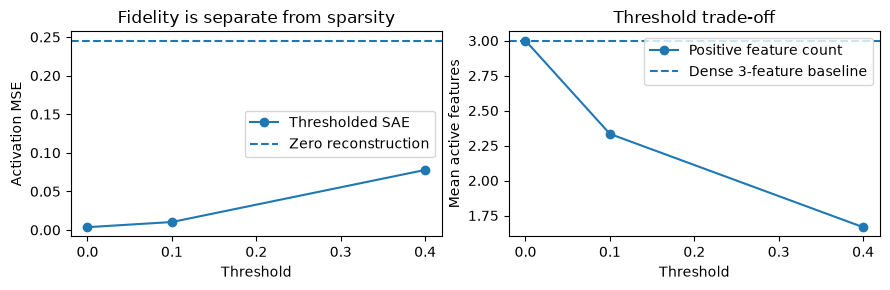

In [9]:
decoder = np.array([[1,0,1,0],[0,1,0,1],[1,1,-1,-1]],dtype=float)
decoder[:2] /= np.sqrt(2);decoder[2] /= 2
residual_axis = np.array([1.,-1.,-1.,1.])/2
latent_codes = np.array([[.8,.6,.2],[.2,.8,.6],[.9,0.,.1]])
activations = latent_codes @ decoder + .12*residual_axis
thresholds = [0.,.1,.4]
errors=[];activity=[]
for threshold in thresholds:
    z = sparse_encode(activations,decoder,threshold)
    errors.append(reconstruction_mse(activations,sparse_decode(z,decoder)))
    activity.append(active_features(z).mean())
print("Thresholds:",thresholds,"MSE:",np.round(errors,6),"mean L0:",np.round(activity,3))
fig,axes=plt.subplots(1,2,figsize=(9,3))
axes[0].plot(thresholds,errors,'o-',label="Thresholded SAE");axes[0].axhline(np.mean(activations**2),ls='--',label="Zero reconstruction")
axes[0].set(xlabel="Threshold",ylabel="Activation MSE",title="Fidelity is separate from sparsity");axes[0].legend()
axes[1].plot(thresholds,activity,'o-',label="Positive feature count");axes[1].axhline(3,ls='--',label="Dense 3-feature baseline")
axes[1].set(xlabel="Threshold",ylabel="Mean active features",title="Threshold trade-off");axes[1].legend();fig.tight_layout();plt.show()

<details><summary>Help - how should I interpret this?</summary>

At threshold zero, error remains 0.0036 because the stripe direction is absent from the dictionary. Raising the threshold cannot recover that direction. The finite three-threshold illustration is an ordinary fixed-function fixture, not a native model or hyperparameter-selection study.

</details>

## Summary of 2️⃣

A low reconstruction error is compatible with an important missing visual component. Loss normalization and per-example activity must be stated before comparing SAEs.

# 3️⃣ Feature interventions without losing the residual

> ##### Learning Objectives
>
> - Implement the visible operations for ablate or amplify one feature while preserving the reconstruction residual.
> - Explain the tensor axes and use an independent small-case check.

If we replace $x$ by a modified reconstruction, we change both the chosen feature and the
reconstruction error. Instead, preserve the residual:
$$x'=x+(z'-z)D.$$
An ablation sets one selected feature to zero; amplification adds a specified amount.
The patch formula leaves $x-zD$ exactly unchanged. At a positive threshold, that residual
includes both genuinely missing directions and the subthreshold part of represented features.

Forecast: for the first image and threshold0.1, does ablating feature0 eliminate **all** red?
What nonzero red component should survive? Write a numerical prediction before the grid.

### Exercise - implement `edit_feature`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return a copied code array with one feature replaced. Preserve all other entries.

In [10]:
def edit_feature(codes, feature, value):
    edited = np.array(codes,copy=True)
    edited[:,feature] = value
    return edited


tests.test_edit_feature(edit_feature)

All tests in test_edit_feature passed!


<details><summary>Hint</summary>

Do not edit the cached codes in place.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_edit_feature passed!`.
An ablation uses value0; value may also broadcast one replacement per example.

</details>

### Exercise - implement `residual_preserving_patch`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement the residual-preserving activation intervention above.

In [11]:
def residual_preserving_patch(activations, original_codes, edited_codes, decoder):
    return np.asarray(activations)+(np.asarray(edited_codes)-np.asarray(original_codes)) @ np.asarray(decoder)


tests.test_residual_preserving_patch(residual_preserving_patch)

All tests in test_residual_preserving_patch passed!


<details><summary>Hint</summary>

Start from the original activation, not the original reconstruction.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_residual_preserving_patch passed!`.
If original and edited codes are identical, return the original activation exactly.

</details>

### Exercise - implement `masked_contrast`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return per-image color contrast in a region, subtracting green from the requested channel. Use channel0 for the left red object and channel2 for the right blue object.

In [12]:
def masked_contrast(images, mask, channel):
    pixels = np.asarray(images)[:,np.asarray(mask,dtype=bool)]
    return (pixels[...,channel]-pixels[...,1]).mean(axis=1)


tests.test_masked_contrast(masked_contrast)

All tests in test_masked_contrast passed!


<details><summary>Hint</summary>

The metric uses image pixels and a spatial mask, never feature activations.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_masked_contrast passed!`.
A gray stripe cancels in this contrast.

</details>

### Exercise - implement `outside_mask_mae`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return per-image RGB MAE outside the target region.

In [13]:
def outside_mask_mae(reference, edited, mask):
    return np.abs(np.asarray(reference)[:,~np.asarray(mask,dtype=bool)]-np.asarray(edited)[:,~np.asarray(mask,dtype=bool)]).mean(axis=(1,2))


tests.test_outside_mask_mae(outside_mask_mae)

All tests in test_outside_mask_mae passed!


<details><summary>Hint</summary>

Keep the target pixels out of the collateral metric.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_outside_mask_mae passed!`.
For one changed background pixel, error is normalized by all outside-mask pixels and channels.

</details>

Target red contrast: [0.56 0.07 0.56 0.  ]
Right blue contrast: [0.42 0.42 0.42 0.35]
Outside-target MAE: [0.      0.      0.00824 0.01359]


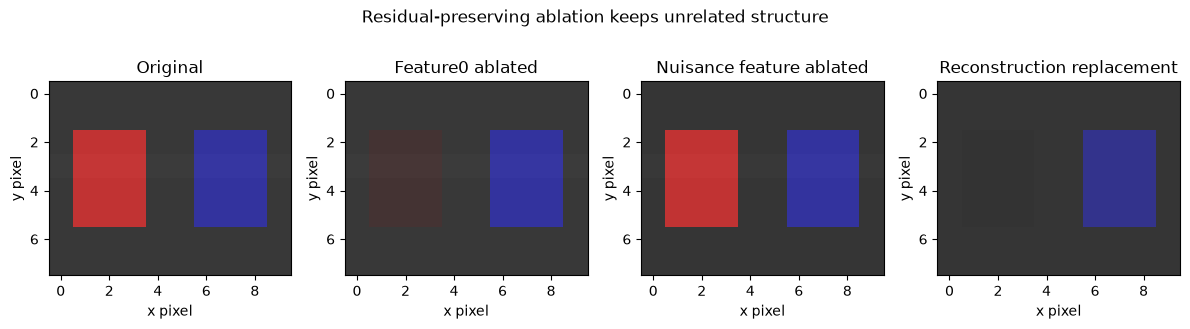

In [14]:
left_mask = np.zeros((8,10),bool);left_mask[2:6,1:4]=True
right_mask = np.zeros((8,10),bool);right_mask[2:6,6:9]=True
x = activations[:1].copy()
z = sparse_encode(x,decoder,.1)
ablated = edit_feature(z,0,0.)
nuisance = edit_feature(z,2,0.)
patched = residual_preserving_patch(x,z,ablated,decoder)
wrong_feature = residual_preserving_patch(x,z,nuisance,decoder)
reconstruction_only = sparse_decode(ablated,decoder)
images = render_sparse_scene(np.concatenate([x,patched,wrong_feature,reconstruction_only]))
print("Target red contrast:",np.round(masked_contrast(images,left_mask,0),3))
print("Right blue contrast:",np.round(masked_contrast(images,right_mask,2),3))
print("Outside-target MAE:",np.round(outside_mask_mae(np.repeat(images[:1],4,axis=0),images,left_mask),5))
utils.image_grid(images,["Original","Feature0 ablated","Nuisance feature ablated","Reconstruction replacement"],"Residual-preserving ablation keeps unrelated structure")
plt.show()

<details><summary>Help - how should I interpret this?</summary>

Target contrast falls from0.56 to0.07, rather than to zero: the threshold placed0.1 of the color factor in the preserved residual. The nuisance feature control leaves target contrast0.56. Reconstruction replacement additionally removes right-object intensity and the stripe; preserving the residual avoids those changes. This image grid with pixel-level specificity scores is the primary signature result.

</details>

## Summary of 3️⃣

Residual preservation makes the intervention interpretable as a feature change. Thresholded encoding can make “feature ablated” weaker than “concept absent.”

# 4️⃣ Correlation, causation and transfer

> ##### Learning Objectives
>
> - Implement the visible operations for measure intervention specificity and distinguish a nuisance correlation from a causal effect.
> - Explain the tensor axes and use an independent small-case check.

A feature can correlate with an image label because of the dataset composition. Compute
$\Delta_f=\mathrm{mean}(z_f\mid y=1)-\mathrm{mean}(z_f\mid y=0)$, but do not call that a
causal effect. In the literal cohort below, background feature2 co-occurs with the red label;
its contrast is larger than feature0's. Our previous intervention already tells us which
feature changes red pixels.

This is a bias **mechanism toy**, with no demographic labels or claim about real-world
fairness. DiffLens uses sparse features to investigate diffusion bias. The lesson's positive
claim is narrower: association ranking alone can identify the wrong intervention target.

### Exercise - implement `feature_contrast`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Return one conditional mean contrast per feature. Reject a cohort missing either group.

In [15]:
def feature_contrast(codes, labels):
    labels = np.asarray(labels,dtype=bool)
    if not labels.any() or labels.all():
        raise ValueError("both label groups required")
    return np.asarray(codes)[labels].mean(axis=0)-np.asarray(codes)[~labels].mean(axis=0)


tests.test_feature_contrast(feature_contrast)

All tests in test_feature_contrast passed!


<details><summary>Hint</summary>

Use the same examples for all feature contrasts.

</details>

<details><summary>Expected output</summary>

The immediate analytic checks print `All tests in test_feature_contrast passed!`.
A perfect association can still be a nuisance correlation.

</details>

Association: [ 0.5 -0.1  0.8] ablated target change: [-0.49  0.    0.  ]


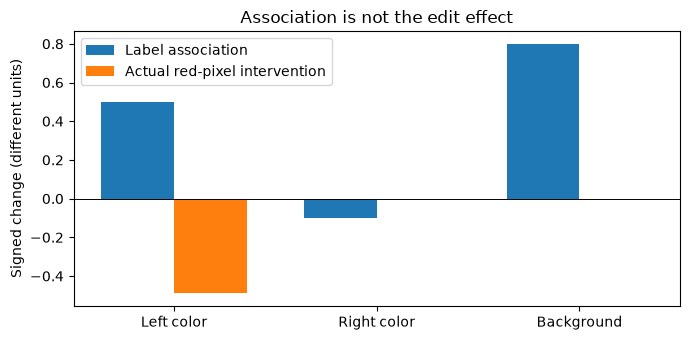

In [16]:
cohort_codes=np.array([[.7,.2,.9],[.6,.4,.8],[.1,.3,0.],[.2,.5,.1]])
labels=np.array([1,1,0,0],bool)
association=feature_contrast(cohort_codes,labels)
# Previously measured intervention scores, not values inferred from association.
causal_red_change=[]
for feature in range(3):
    changed=residual_preserving_patch(x,z,edit_feature(z,feature,0.),decoder)
    causal_red_change.append(float(masked_contrast(render_sparse_scene(changed),left_mask,0)[0]-masked_contrast(render_sparse_scene(x),left_mask,0)[0]))
print("Association:",association.round(3),"ablated target change:",np.round(causal_red_change,3))
fig,ax=plt.subplots(figsize=(7,3.5));positions=np.arange(3)
ax.bar(positions-.18,association,width=.36,label="Label association")
ax.bar(positions+.18,causal_red_change,width=.36,label="Actual red-pixel intervention")
ax.axhline(0,color='black',lw=.7);ax.set(xticks=positions,xticklabels=["Left color","Right color","Background"],ylabel="Signed change (different units)",title="Association is not the edit effect")
ax.legend();fig.tight_layout();plt.show()

<details><summary>Help - how should I interpret this?</summary>

Feature2 has label contrast0.8 but zero target-red effect; feature0 has contrast0.5 and target change-0.49. These bars have explicitly different units. They compare ranking and sign, not calibrated magnitudes. Swapping labels reverses associations while leaving the measured intervention unchanged.

</details>

## Try it yourself

Change only the encoding threshold from0.1 to0.4. Predict the remaining left-object contrast
after feature0 ablation. Does preserving a larger residual make the apparent ablation weaker?
Also reverse the labels in the cohort: association should flip, but the causal image edit
should not. Record your forecast before checking the public result.

Remaining red contrast: [0.28]
Reversed-label associations: [-0.5  0.1 -0.8]


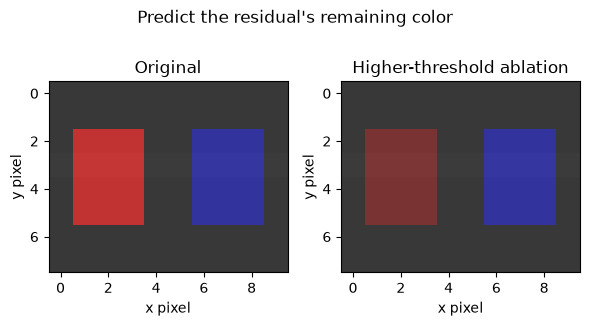

In [17]:
play_threshold=.4
play_codes=sparse_encode(x,decoder,play_threshold)
play_patch=residual_preserving_patch(x,play_codes,edit_feature(play_codes,0,0.),decoder)
print("Remaining red contrast:",masked_contrast(render_sparse_scene(play_patch),left_mask,0).round(3))
print("Reversed-label associations:",feature_contrast(cohort_codes,~labels).round(3))
utils.image_grid(render_sparse_scene(np.concatenate([x,play_patch])),["Original","Higher-threshold ablation"],"Predict the residual's remaining color")
plt.show()

## Summary of 4️⃣

Use conditional activation scores to propose a feature, and independently scored interventions to test it. Keep reconstruction errors and data composition visible.

# ☆ Bonus

## Limits and source connection

This study edition implements SAE
forward equations, normalized objective, decoder gradients, sparsity diagnostics, association
and feature steering on explicit image-generating activations. Training SAEs on native UNet
or DiT activations, collecting timestep-conditioned features and validating diffusion bias
interventions remain pending. The known dictionary is not a learned explanation.

DiffLens decomposes hidden activations with an SAE to study bias-related components. A native
follow-on needs the exact checkpoint/layer/timestep distribution, reconstruction baseline,
feature selection data, controlled prompts and an independent image scorer. Avoid selecting
features and reporting their effects on the same examples as an untouched evaluation.

Anomaly hunt: rotate the dictionary rows while preserving the spanned subspace. Which
reconstruction metrics can remain unchanged while sparse feature interpretations change?

## Further reading

- [Dissecting and Mitigating Diffusion Bias via Mechanistic Interpretability (DiffLens)](https://openaccess.thecvf.com/content/CVPR2025/papers/Shi_Dissecting_and_Mitigating_Diffusion_Bias_via_Mechanistic_Interpretability_CVPR_2025_paper.pdf).
- [Towards Monosemanticity: Decomposing Language Models With Dictionary Learning](https://transformer-circuits.pub/2023/monosemantic-features/index.html).
- [SAeUron: Interpretable Concept Unlearning in Diffusion Models with Sparse Autoencoders](https://arxiv.org/abs/2501.18052).